In [4]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 1 - Diffusive and dispersive schemes for a gaussian signal

## Run the simulation

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [405]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00



cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_gauss_ubs.*
rm CANAL_gauss_fct2.*
rm CANAL_gauss_fct4.*

chmod -R a+x /"$DIR"/demo_gauss/

bash /"$DIR"/demo_gauss/gauss_istate.sh "$DIR"
bash /"$DIR"/demo_gauss/gauss_cfg.sh "$DIR"
bash /"$DIR"/demo_gauss/lambda_run.sh "$DIR" "25 50 100 200"
    

106a107
>             pts(:,:,jk,jp_sal) = 30._wp+5._wp*EXP( -0.5_wp *glamt(:,:)**2 / rn_lambda**2 )
Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
Compilation form : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

Process is interrupted.


## Comparative plots

### Salinity variance

In [5]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


In [19]:
lambda_list = [25, 50, 100, 200]
scheme_list = ['ubs', 'fct2', 'fct4']

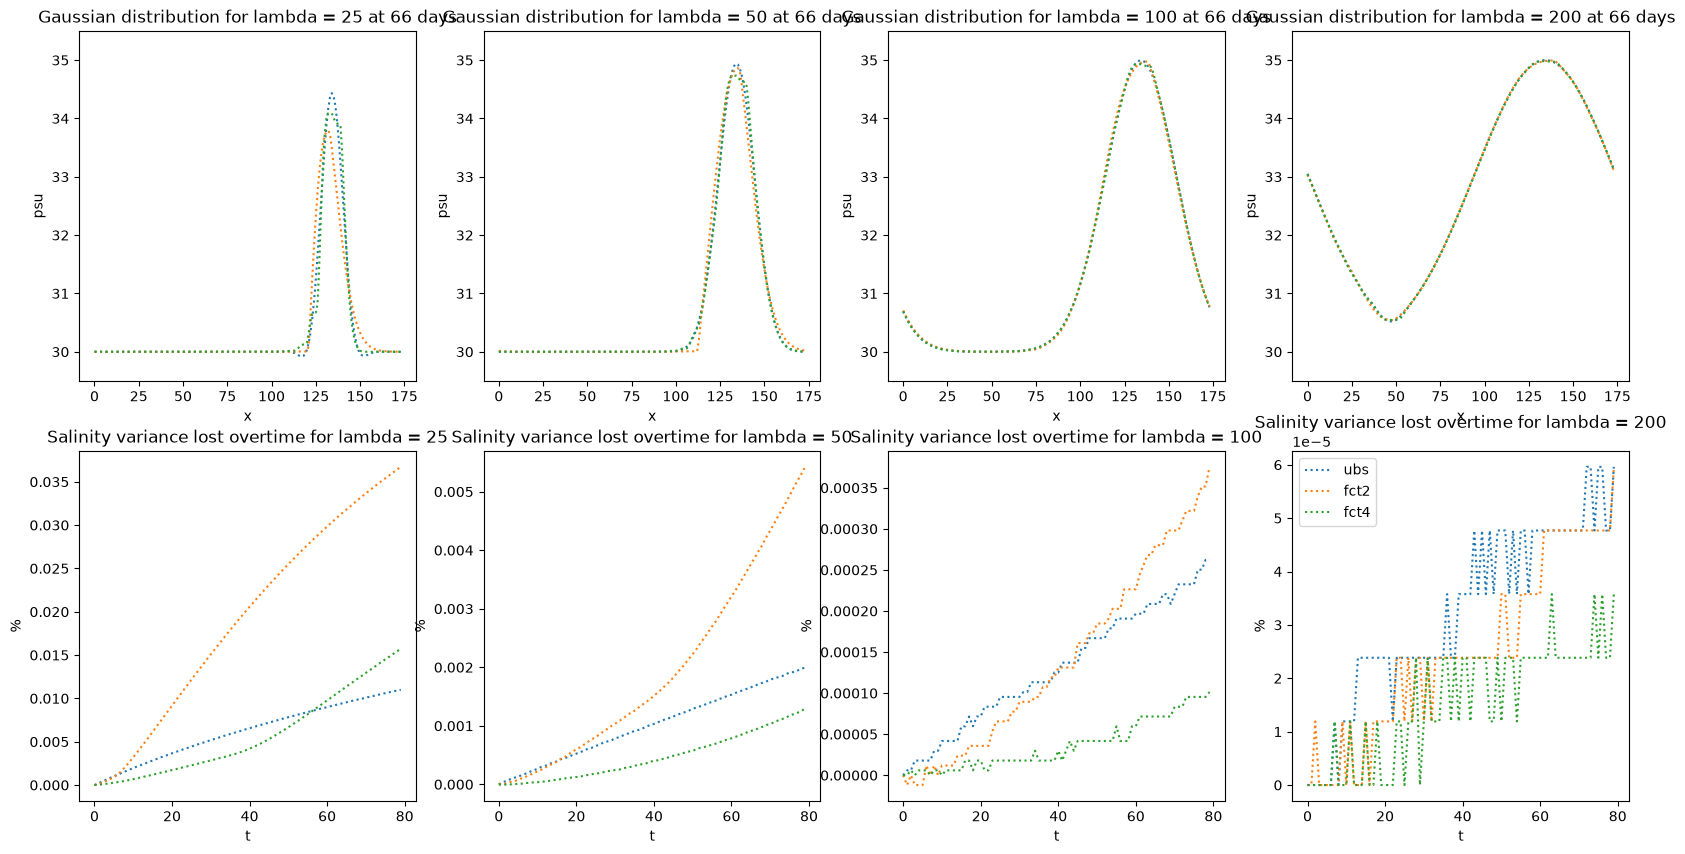

In [35]:
fig_salt2c, axes_salt2c = plt.subplots(2, len(lambda_list), figsize=(20,10)) 

for i, l in enumerate(lambda_list):
        for scheme in scheme_list :
            dataset = xr.open_dataset(rep+'CANAL_gauss_'+scheme+'.'+str(l)+'_all_grid.nc', decode_times=False)
            s2c = dataset['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
            s2c = np.array(s2c)
            data = (1-s2c/s2c[0])*100
            time = np.arange(s2c.shape[0])
            axes_salt2c[1][i].plot(time,  data, ':', label = scheme)#plotting the ratio of the lost variance
            axes_salt2c[1][i].set_title(f"Salinity variance lost overtime for lambda = {l}")
            axes_salt2c[1][i].set_xlabel('t')
            axes_salt2c[1][i].set_ylabel('%')
            gauss = dataset['soce'].isel(time_counter=65, y_grid_T = 50, deptht=0)
            x = np.arange(gauss.shape[0])
            axes_salt2c[0][i].plot(x, gauss, ':')
        axes_salt2c[0][i].set_title(f"Gaussian distribution for lambda = {l} at 66 days")
        axes_salt2c[0][i].set_ylim(29.5,35.5)
        axes_salt2c[0][i].set_xlabel('x')
        axes_salt2c[0][i].set_ylabel('psu')
plt.legend()


### Phase speed

In [37]:
cen2 = xr.open_dataset(rep+'CANAL_gauss_cen2.100_all_grid.nc', decode_times=False)
ubs = xr.open_dataset(rep+'CANAL_gauss_ubs.100_all_grid.nc', decode_times=False)
fct2 = xr.open_dataset(rep+'CANAL_gauss_fct2.100_all_grid.nc', decode_times=False)
fct4 = xr.open_dataset(rep+'CANAL_gauss_fct4.100_all_grid.nc', decode_times=False)

In [56]:
schemes = {'cen2': cen2, 'ubs': ubs, 'fct2' :fct2, 'fct4' : fct4}
soce = {n: ds['soce'].isel(y_grid_T=50, deptht=0).values
          for n, ds in schemes.items()}

/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/1191518488.py:11: RuntimeWarning: divide by zero encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt with numpy convention
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_46637/1191518488.py:11: RuntimeWarning: invalid value encountered in divide
  dphi = np.angle(F[1:] / F[:-1])          # = -ω dt with numpy convention


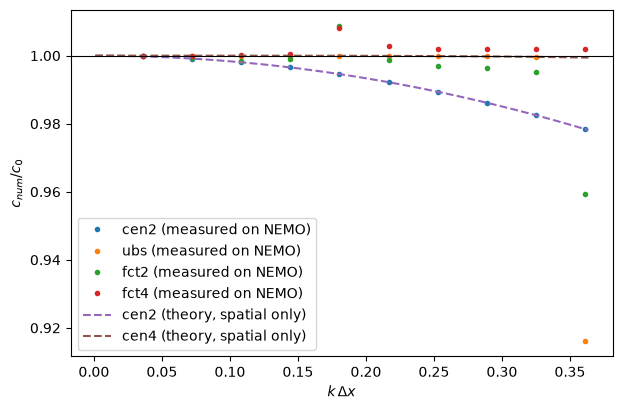

In [57]:
dx = 5000 #[m]
dt = 24*3600 #[s]
c0 = 0.5 #[m/s]
theta_max = min(np.pi, np.pi*dx/(c0*dt)) #maximum value of theta to avoid spectral aliasing
k_max = theta_max/dx

def phase_speed(f, dx, dt):
    """f[t, x] -> k, c(k) mesuré par la rotation de phase entre pas de temps."""
    F = np.fft.rfft(f - f.mean(axis=1, keepdims=True), axis=1)
    k = 2*np.pi*np.fft.rfftfreq(f.shape[1], dx)
    dphi = np.angle(F[1:] / F[:-1])          # = -ω dt with numpy convention 
    w = np.abs(F[1:] * F[:-1])               # amplitude weighting
    c = np.full(k.shape, np.nan)
    for i in range(1, len(k)):
        c[i] = -np.sum(w[:, i] * dphi[:, i]) / (np.sum(w[:, i]) * k[i] * dt)
    return k, c

theta = np.linspace(1e-3, theta_max, 400)                       # θ = k·dx
theory = { #theoretical expression of c_p = ω/k for CEN2 and CEN4 for spatial discretisation only
    'cen2': np.sin(theta) / theta, 
    'cen4': (4/3*np.sin(theta) - 1/6*np.sin(2*theta)) / theta,
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, f in soce.items():
    k, c = phase_speed(f, dx, dt)
    k=k[ k < k_max]
    c = c[:len(k)]
    ax.plot(k*dx, c / c0, '.', label=f'{name} (measured on NEMO)')
for name, c_th in theory.items():
    ax.plot(theta, c_th, '--', label=f'{name} (theory, spatial only)')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel(r'$k\,\Delta x$')
ax.set_ylabel(r'$c_{num}/c_0$')
ax.legend()
plt.show()

### Salinity

In [58]:
schemes = { 'fct2' : fct2, 'fct4' : fct4,  'ubs': ubs}
colors = {'cen2': 'red', 'cen4': 'orange',  'fct2' : 'green', 'fct4' : 'lightgreen', 'ubs': 'blue'}

soce = {n: ds['soce'].isel(y_grid_T=50, deptht=0).values
          for n, ds in schemes.items()}
g = {n: ds['sssgrad'].isel(y_grid_T=50).values
          for n, ds in schemes.items()}

In [59]:
gauss_0 = xr.open_dataset(rep+'CANAL_gauss_traadvOFF.100_all_grid.nc', decode_times=False)
gauss_0 =gauss_0.soce.isel(y_grid_T = 50, time_counter=0, deptht=0)

v= 0.5
dx = 5000
ref = []

for t in range (80):
    ref.append(np.roll(gauss_0, shift=v*86400*(t+1)/dx))
    


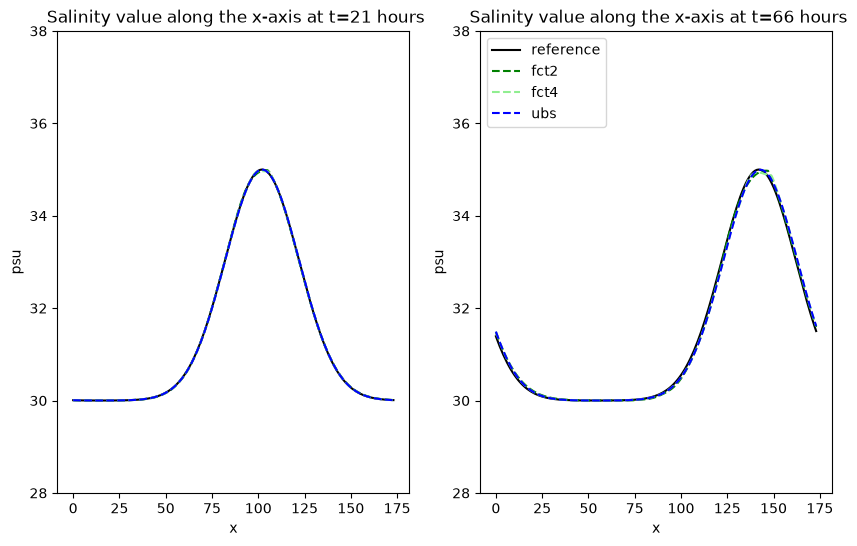

In [60]:
t_list = [21, 66]

fig, ax = plt.subplots(1, len(t_list), figsize=(10,6))

for i,t in enumerate(t_list):
    ax[i].plot(np.arange(len(ref[0])), ref[t], color ='black', label ='reference')
    for n, ds in soce.items() :
        ax[i].plot(np.arange(ds.shape[1]), ds[t], '--', color = colors[n], label = n)
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('psu')
    ax[i].set_ylim(28,38)
    ax[i].set_title(f' Salinity value along the x-axis at t={t} hours')


plt.legend(loc='upper left')

### Salinity gradient

In [62]:
gauss_0 = xr.open_dataset(rep+'CANAL_gauss_traadvOFF.100_all_grid.nc').sssgrad.isel(y_grid_T = 50, time_counter = 0)

ref_grad = []

for t in range (80):
    ref_grad.append(np.roll(gauss_0, shift=v*86400*(t+0.5)/dx)) 


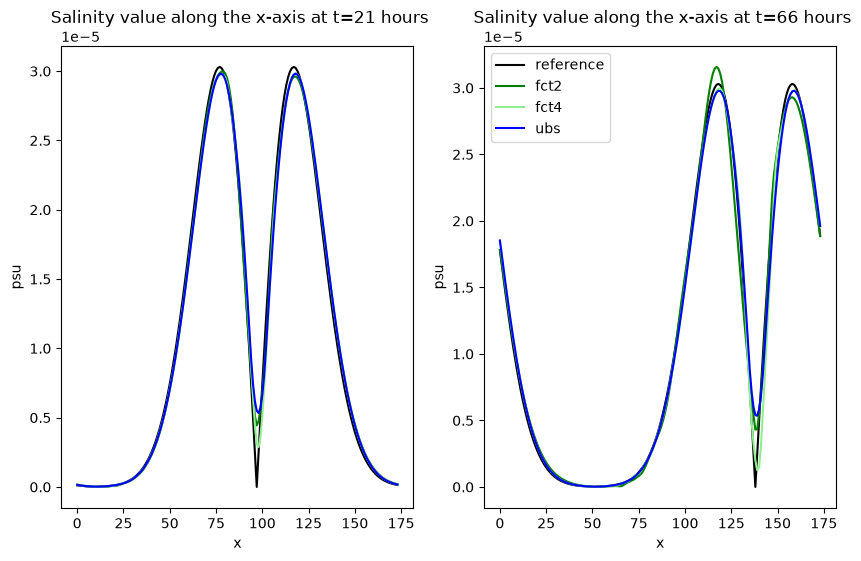

In [63]:
t_list = [21, 66]

fig, ax = plt.subplots(1, len(t_list), figsize=(10,6))

for i,t in enumerate(t_list):
    ax[i].plot(np.arange(len(ref_grad[0])), ref_grad[t], color ='black', label ='reference')
    for n, ds in g.items() :
        ax[i].plot(np.arange(ds.shape[1]), ds[t], color = colors[n], label = n)
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('psu')
    ax[i].set_title(f' Salinity value along the x-axis at t={t} hours')


plt.legend(loc='upper left')

In [59]:
cen2.close()
ubs.close()
fct2.close()

In [124]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

bash /"$DIR"/demo_gauss/end_gauss.sh "$DIR"

+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ DIR_PARENT=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ TMP=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 ']'
+ awk '
/pts\(:,:,jk,jp_sal\).*EXP.*rn_lambda/ {next}
{print}
' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp
+ cp /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
+ mv /Users/jbuisson

Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak


+ cd /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
+ echo Compiling
+ ./makenemo -r CANAL -n EXP42


Compiling
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC content is linked to /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK

--------------------------------------------------------------------------------
Compilation
--------------------------------------------------------------------------------

Build command started on Thu Oct  8 15:16:39 2026.
->Parse configuration: start
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/bld.cfg
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/arch_nemo.fcm
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/cpp.fcm
->Parse configuration: 1 second
->Setup destination: start
De

Use of uninitialized value in numeric gt (>) at /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/ext/FCM/bin/../lib/Fcm/BuildTask.pm line 176.


No. of pre-processed file: 1
->Pre-process: 0 second
->Scan dependency: start
No. of file scanned for dependency: 1
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/Makefile: updated
->Scan dependency: 0 second
->Generate Fortran interface: start
->Generate Fortran interface: 0 second
->Make: start
mpif90-mpich-gcc15 -o usrdef_istate.o -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/inc -fdefault-real-8 -march=native -O2 -fno-expensive-optimizations -funroll-all-loops -fcray-pointer -ffree-line-length-none -fallow-argument-mismatch -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/inc -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/include -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/include -c /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/ppsrc/nemo/usrdef_istate.f90
mpif90-mpich-gcc15 -o restart.o -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/inc -fdefault-real-8 -march=native 

ar: creating archive /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(cyclone.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(defprec.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(ioipsl.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(obs_const.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(par_kind.o) has no symbols
/Library/Developer/CommandLineTools

mpif90-mpich-gcc15 -o nemo.exe /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/obj/nemo.o -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/lib -l__fcm__nemo -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/lib -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/lib -lxios -lstdc++ -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lnetcdff -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lnetcdf -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lhdf5_hl -lhdf5 -L/opt/local/lib -lcurl  -lz  -lm
->Make: 113 seconds
->TOTAL: 114 seconds
Build command finished on Thu Oct  8 15:18:33 2026.

--------------------------------------------------------------------------------
Compilation successful
------------------------------------------------------------------